<a href="https://colab.research.google.com/github/TimothyKeng/Timothy_INFO4670_Falls2026/blob/main/Assingment4_LogisticRegressionCar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Code to upload and load the CSV file in Google Colab
from google.colab import files
uploaded = files.upload()

# Load the uploaded file (assuming the filename is 'car_purchase_data.csv')
df = pd.read_csv('car_purchase_data.csv')
df.head()

Saving car_purchase_data.csv to car_purchase_data (1).csv


,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


### Step 2: Split features and target

In [8]:
x = df[['Age', 'Salary']]
y = df['Purchased']

### Step 3: Train/Test Split

In [21]:
# Perform a 75/25 train/test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=0)

# Print the shape of the split datasets to verify
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")

x_train shape: (300, 2)
x_test shape: (100, 2)


### Step 4: Feature Scaling

In [22]:
scaler= StandardScaler()
x_train= scaler.fit_transform(x_train)
x_test= scaler.transform(x_test)

print('Scaling complete')

Scaling complete


### Step 5: Train Logistic Regression Model

In [23]:
model= LogisticRegression()
model.fit(x_train, y_train)
print('Model trained')

Model trained


### Step 6: Predict and Evaluate

In [24]:
y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred) # confusion matrix

print('Accuracy:', accuracy)
print('Confusion Matrix:\n', conf_matrix)
print('Classification Report:\n', classification_report(y_test, y_pred))

Accuracy: 0.89
Confusion Matrix:
 [[65  3]
 [ 8 24]]
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.96      0.92        68
           1       0.89      0.75      0.81        32

    accuracy                           0.89       100
   macro avg       0.89      0.85      0.87       100
weighted avg       0.89      0.89      0.89       100



### Step 7: Visualization of Decision Regions

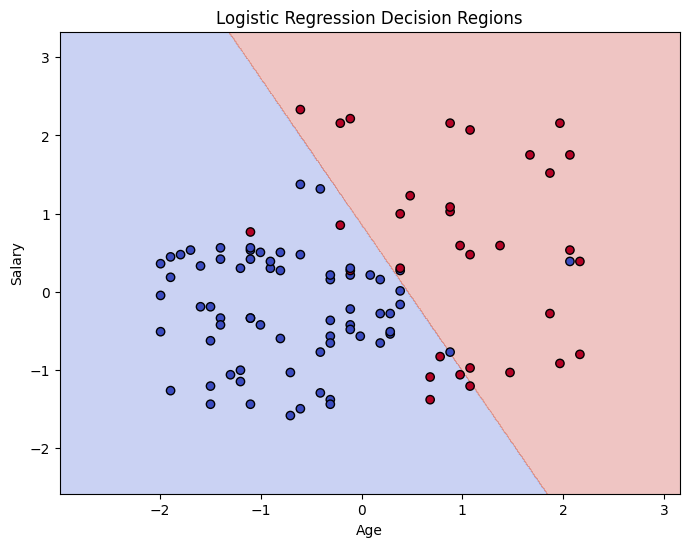

In [25]:
# Convert x_test to a NumPy array so we can use 2D slicing syntax [:, 0]
x_set = x_test
Y_set = y_test.values

x1_min, x1_max = x_set[:, 0].min() - 1, x_set[:, 0].max() + 1
x2_min, x2_max = x_set[:, 1].min() - 1, x_set[:, 1].max() + 1

X1, X2 = np.meshgrid(
    np.arange(x1_min, x1_max, 0.01),
    np.arange(x2_min, x2_max, 0.01)
)

Z = model.predict(
    np.array([X1.ravel(), X2.ravel()]).T
)

Z = Z.reshape(X1.shape)

plt.figure(figsize=(8,6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(x_set[:, 0], x_set[:, 1], c=Y_set, cmap='coolwarm', edgecolors='k')

plt.title('Logistic Regression Decision Regions')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1. The predicted probability is compared to a cutoff, usually .5. If the probability is .5 or higher, the customer is classified as a purchaser if not, they are classified as a non-purchaser
2. Based on the model, customers with age and salary that fall within the predicted purchase region are more likley to purchase a car. The model has an accuracy of 89%, showing that age and salary were useful for predicting customers purchasing cars.
3. Age and salary may not fully explain whether someone purchases a car. There can also be a overlap between customers who do and don't purchase, outliers, or uneven number of purchases/non-purchases.
4. Features such as income, employment status, current vehicle ownership, or previous purchase history could improve the model. Checking for missing values, outliers, and cross validating could also help the accuracy and model reliability